# RiyalPay — `exp_kyc_streamline_2026` Analysis

**Experiment:** shortened KYC flow (auto document scan, fewer form fields) vs. existing flow.
**Window:** 2026-02-02 – 2026-03-16 (6 weeks). **Primary metric:** KYC approval rate.
**Secondary metric:** downstream activation rate (first successful transaction).

This notebook does **not** start with the topline lift. It starts with whether the experiment
is trustworthy at all — assignment integrity first, then effect estimation with proper
uncertainty, then a check for pitfalls (novelty effects, contamination, platform imbalance)
before any go/no-go recommendation.

In [1]:
import sqlite3
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.stats.api as sms
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
conn = sqlite3.connect('E:/Sidra/JupyterProjects/RiyalPay-Project/riyalpay.db')
print('Connected.')

Connected.


## 1. Assignment integrity checks

Before touching outcomes: is the randomization itself trustworthy?

In [2]:
assignments = pd.read_sql('''
    SELECT user_id, experiment_id, variant, assignment_date, platform, is_contaminated
    FROM clean_experiment_assignments
''', conn)

print(f"Total assigned users: {len(assignments):,}")
print(f"Contaminated (assigned to both arms in raw log): {assignments['is_contaminated'].sum()} "
      f"({assignments['is_contaminated'].mean()*100:.2f}%)")

clean_assign = assignments[assignments['is_contaminated'] == 0].copy()
print(f"Analysis population after excluding contamination: {len(clean_assign):,}")

Total assigned users: 6,012
Contaminated (assigned to both arms in raw log): 43 (0.72%)
Analysis population after excluding contamination: 5,969


### 1a. Sample Ratio Mismatch (SRM) check

If randomization is working, the control/treatment split should be close to the intended
50/50 in **every** slice that shouldn't affect assignment — including platform. A chi-square
goodness-of-fit test checks whether the observed split is consistent with 50/50.

In [3]:
def srm_check(df, label):
    counts = df['variant'].value_counts()
    n_control, n_treatment = counts.get('control', 0), counts.get('treatment', 0)
    total = n_control + n_treatment
    expected = [total/2, total/2]
    chi2, p = stats.chisquare([n_control, n_treatment], f_exp=expected)
    flag = "*** SRM DETECTED ***" if p < 0.01 else "OK"
    print(f"{label:20s}  control={n_control:5d}  treatment={n_treatment:5d}  "
          f"ratio={n_control/total:.1%}/{n_treatment/total:.1%}  chi2={chi2:.2f}  p={p:.2e}   {flag}")
    return p

print("SRM check (p < 0.01 is a red flag — a well-randomized 50/50 split essentially never")
print("produces a p-value that small by chance):\n")
srm_check(clean_assign, "Overall")
srm_check(clean_assign[clean_assign.platform=='iOS'], "iOS only")
srm_check(clean_assign[clean_assign.platform=='Android'], "Android only")

SRM check (p < 0.01 is a red flag — a well-randomized 50/50 split essentially never
produces a p-value that small by chance):

Overall               control= 3374  treatment= 2595  ratio=56.5%/43.5%  chi2=101.67  p=6.57e-24   *** SRM DETECTED ***
iOS only              control= 1055  treatment= 1175  ratio=47.3%/52.7%  chi2=6.46  p=1.10e-02   OK
Android only          control= 2319  treatment= 1420  ratio=62.0%/38.0%  chi2=216.15  p=6.24e-49   *** SRM DETECTED ***


np.float64(6.24104876202937e-49)

### Finding: SRM on Android, not iOS

The overall and Android-specific splits fail the SRM check decisively; iOS does not. A platform-
specific SRM points to a platform-specific assignment bug (e.g. device-ID re-hashing), not
general randomization failure — worth flagging to engineering separately.

**Note on the iOS result:** its own SRM p-value (~0.011) is not far above the 0.01 threshold
used here. With a true 50/50 randomizer, a split this skewed happens by chance more often than
people intuit — this is exactly the kind of borderline case worth re-checking on a longer
history (e.g. all-time iOS assignment ratios for this app) before concluding iOS is clean,
rather than accepting a single p-value at face value.

**Implication for analysis:** a pooled readout across both platforms is not trustworthy, because
the Android arm is not a clean random split. The two defensible options are:
1. Analyze **iOS only**, where randomization held.
2. Investigate and fix the Android assignment bug, re-run, and analyze together.

This notebook proceeds primarily on **iOS**, and reports Android numbers only descriptively —
not as evidence.

## 2. Primary outcome: KYC approval rate (iOS only, clean population)

In [4]:
kyc = pd.read_sql('''
    SELECT user_id, MAX(CASE WHEN event_name='kyc_approved' THEN 1 ELSE 0 END) AS approved
    FROM clean_events WHERE is_suspected_bot = 0 GROUP BY user_id
''', conn)

ios = clean_assign[clean_assign.platform == 'iOS'].merge(kyc, on='user_id', how='left')
ios['approved'] = ios['approved'].fillna(0).astype(int)

summary = ios.groupby('variant')['approved'].agg(['sum', 'count', 'mean']).rename(
    columns={'sum': 'n_approved', 'count': 'n_assigned', 'mean': 'approval_rate'})
summary['approval_rate'] = (summary['approval_rate'] * 100).round(2)
summary

,n_approved,n_assigned,approval_rate
variant,,,
control,576,1055,54.60
treatment,749,1175,63.74


### 2a. Two-proportion z-test + 95% confidence interval

In [5]:
ctrl = ios[ios.variant == 'control']['approved']
trt  = ios[ios.variant == 'treatment']['approved']

count = np.array([trt.sum(), ctrl.sum()])
nobs  = np.array([len(trt), len(ctrl)])

z_stat, p_val = proportions_ztest(count, nobs)
ci_trt  = proportion_confint(trt.sum(), len(trt), alpha=0.05, method='wilson')
ci_ctrl = proportion_confint(ctrl.sum(), len(ctrl), alpha=0.05, method='wilson')

diff = trt.mean() - ctrl.mean()
# CI for the difference (Wald, normal approx)
se_diff = np.sqrt(trt.mean()*(1-trt.mean())/len(trt) + ctrl.mean()*(1-ctrl.mean())/len(ctrl))
ci_diff = (diff - 1.96*se_diff, diff + 1.96*se_diff)

print(f"Treatment approval rate: {trt.mean():.1%}  (95% CI {ci_trt[0]:.1%} - {ci_trt[1]:.1%}), n={len(trt)}")
print(f"Control approval rate:   {ctrl.mean():.1%}  (95% CI {ci_ctrl[0]:.1%} - {ci_ctrl[1]:.1%}), n={len(ctrl)}")
print(f"\nAbsolute lift: {diff:+.1%}  (95% CI {ci_diff[0]:+.1%} to {ci_diff[1]:+.1%})")
print(f"z = {z_stat:.2f}, p = {p_val:.4f}")
print(f"\nResult: {'statistically significant at alpha=0.05' if p_val < 0.05 else 'NOT statistically significant'}")

Treatment approval rate: 63.7%  (95% CI 61.0% - 66.4%), n=1175
Control approval rate:   54.6%  (95% CI 51.6% - 57.6%), n=1055

Absolute lift: +9.1%  (95% CI +5.1% to +13.2%)
z = 4.39, p = 0.0000

Result: statistically significant at alpha=0.05


### 2b. Statistical power of this read

Given the achieved sample size (iOS only), what's the smallest true effect we could reliably
detect? If the observed lift is close to that floor, treat the point estimate cautiously even
when the p-value clears 0.05.

In [6]:
analysis = NormalIndPower()
n_per_arm = min(len(ios[ios.variant=='control']), len(ios[ios.variant=='treatment']))
baseline_p = ctrl.mean()

# achieved power for the OBSERVED effect size
observed_h = 2*np.arcsin(np.sqrt(trt.mean())) - 2*np.arcsin(np.sqrt(baseline_p))  # Cohen's h
achieved_power = analysis.power(effect_size=abs(observed_h), nobs1=n_per_arm, alpha=0.05, ratio=1)

# minimum detectable effect at 80% power, given the achieved sample size
mde_h = analysis.solve_power(nobs1=n_per_arm, alpha=0.05, power=0.80, ratio=1)
# convert Cohen's h back to an approximate proportion lift around baseline_p
mde_p_upper = (np.sin((2*np.arcsin(np.sqrt(baseline_p)) + mde_h)/2))**2
mde_pp = (mde_p_upper - baseline_p) * 100

print(f"iOS sample size per arm: ~{n_per_arm}")
print(f"Achieved power for the observed effect: {achieved_power:.1%}")
print(f"Minimum detectable effect at 80% power, alpha=0.05: ~{mde_pp:.1f} percentage points")
print(f"Observed lift was: {diff*100:.1f} percentage points")

iOS sample size per arm: ~1055
Achieved power for the observed effect: 99.0%
Minimum detectable effect at 80% power, alpha=0.05: ~6.0 percentage points
Observed lift was: 9.1 percentage points


## 3. Secondary outcome: downstream activation rate (iOS only)

The metric leadership actually cares about is activation, not KYC approval in isolation.

In [7]:
activated = pd.read_sql("SELECT DISTINCT user_id, 1 AS activated FROM clean_transactions WHERE status='success'", conn)
ios_act = clean_assign[clean_assign.platform == 'iOS'].merge(activated, on='user_id', how='left')
ios_act['activated'] = ios_act['activated'].fillna(0).astype(int)

ctrl_a = ios_act[ios_act.variant=='control']['activated']
trt_a  = ios_act[ios_act.variant=='treatment']['activated']
z2, p2 = proportions_ztest([trt_a.sum(), ctrl_a.sum()], [len(trt_a), len(ctrl_a)])
diff_a = trt_a.mean() - ctrl_a.mean()

print(f"Treatment activation rate: {trt_a.mean():.1%}, n={len(trt_a)}")
print(f"Control activation rate:   {ctrl_a.mean():.1%}, n={len(ctrl_a)}")
print(f"Absolute lift: {diff_a:+.1%}   z={z2:.2f}  p={p2:.4f}")
print(f"Result: {'significant' if p2 < 0.05 else 'not significant'} at alpha=0.05")

Treatment activation rate: 61.8%, n=1175
Control activation rate:   53.3%, n=1055
Absolute lift: +8.5%   z=4.07  p=0.0000
Result: significant at alpha=0.05


## 4. Novelty-effect check: is the lift stable across the 6-week window?

A treatment effect that's large in week 1 and decays toward zero by week 6 suggests users
were reacting to *novelty*, not a durable improvement — a classic experiment pitfall.

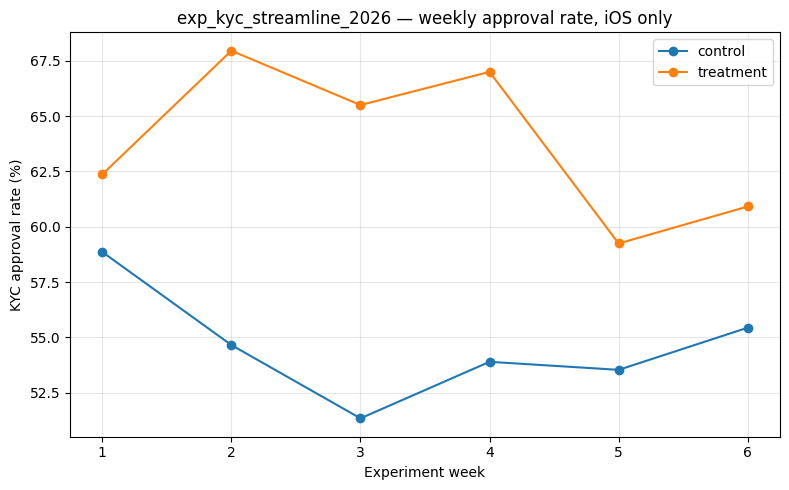

variant,control,treatment
week,,
1,58.9,62.4
2,54.7,68.0
3,51.3,65.5
4,53.9,67.0
5,53.5,59.2
6,55.4,60.9


In [8]:
weekly = pd.read_sql('''
    WITH kyc_outcome AS (
      SELECT user_id, MIN(CASE WHEN event_name='kyc_approved' THEN event_timestamp END) AS approved_ts
      FROM clean_events WHERE is_suspected_bot = 0 GROUP BY user_id
    )
    SELECT ea.variant, ea.platform,
           CAST(((JULIANDAY(ea.assignment_date) - JULIANDAY('2026-02-02')) / 7) AS INT) + 1 AS week,
           COUNT(*) AS n_assigned,
           SUM(CASE WHEN k.approved_ts IS NOT NULL THEN 1 ELSE 0 END) AS n_approved
    FROM clean_experiment_assignments ea
    LEFT JOIN kyc_outcome k ON k.user_id = ea.user_id
    WHERE ea.is_contaminated = 0 AND ea.platform = 'iOS'
    GROUP BY ea.variant, week ORDER BY week, ea.variant
''', conn)
weekly['approval_rate'] = weekly['n_approved'] / weekly['n_assigned']

fig, ax = plt.subplots(figsize=(8,5))
for variant, grp in weekly.groupby('variant'):
    ax.plot(grp['week'], grp['approval_rate']*100, marker='o', label=variant)
ax.set_xlabel('Experiment week')
ax.set_ylabel('KYC approval rate (%)')
ax.set_title('exp_kyc_streamline_2026 — weekly approval rate, iOS only')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('novelty_check_ios.png', dpi=120)
plt.show()
weekly.pivot(index='week', columns='variant', values='approval_rate').round(3) * 100

### 4a. Is the narrowing in the last two weeks real?

The treatment–control gap is not constant: it is smallest in week 1, around +13 pts in weeks 2–4,
and about +5.5 pts in weeks 5–6. That is not the classic novelty pattern (large at the start, then
decaying), but it deserves a test rather than an eyeball. Each weekly point rests on only about
170–210 users per arm, so the intervals below are wide.

In [9]:
# Weekly treatment-minus-control gap on iOS, with 95% Wald intervals
w = weekly.pivot(index='week', columns='variant', values=['n_assigned', 'n_approved'])
nC, nT = w['n_assigned']['control'], w['n_assigned']['treatment']
pC, pT = w['n_approved']['control'] / nC, w['n_approved']['treatment'] / nT
gap = pT - pC
se = np.sqrt(pT * (1 - pT) / nT + pC * (1 - pC) / nC)
gap_tbl = pd.DataFrame({
    'n_control': nC, 'n_treatment': nT,
    'gap_pts': (gap * 100).round(1),
    'ci_low': ((gap - 1.96 * se) * 100).round(1),
    'ci_high': ((gap + 1.96 * se) * 100).round(1),
})
display(gap_tbl)

def gap_for(weeks):
    d = weekly[weekly['week'].isin(weeks)].groupby('variant')[['n_assigned', 'n_approved']].sum()
    pc = d.loc['control', 'n_approved'] / d.loc['control', 'n_assigned']
    pt = d.loc['treatment', 'n_approved'] / d.loc['treatment', 'n_assigned']
    s = np.sqrt(pt * (1 - pt) / d.loc['treatment', 'n_assigned'] + pc * (1 - pc) / d.loc['control', 'n_assigned'])
    return pt - pc, s

def compare(weeks_a, weeks_b, label):
    ga, sa = gap_for(weeks_a)
    gb, sb = gap_for(weeks_b)
    z = (ga - gb) / np.sqrt(sa ** 2 + sb ** 2)
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    print(f'{label}: gap {ga*100:+.1f} pts vs {gb*100:+.1f} pts -> difference z = {z:.2f}, p = {p:.2f}')

print()
compare([1, 2, 3], [4, 5, 6], 'Pre-specified halves (weeks 1-3 vs 4-6)')
compare([2, 3, 4], [5, 6], 'Post-hoc split chosen after viewing the chart (weeks 2-4 vs 5-6)')

,n_control,n_treatment,gap_pts,ci_low,ci_high
week,,,,,
1,175,186,3.5,-6.6,13.6
2,172,181,13.3,3.2,23.4
3,187,200,14.2,4.4,23.9
4,167,200,13.1,3.1,23.1
5,170,211,5.7,-4.3,15.7
6,184,197,5.5,-4.4,15.4



Pre-specified halves (weeks 1-3 vs 4-6): gap +10.4 pts vs +8.0 pts -> difference z = 0.57, p = 0.57
Post-hoc split chosen after viewing the chart (weeks 2-4 vs 5-6): gap +13.5 pts vs +5.5 pts -> difference z = 1.73, p = 0.08


**Reading this:**
- Treatment is ahead of control in all six weeks, but in weeks 1, 5 and 6 the weekly gap on its own
  is not distinguishable from zero (its interval includes 0), as expected with about 170–210 users per arm.
- A split into halves decided in advance (weeks 1–3 vs 4–6) shows no meaningful change in the gap
  (p ≈ 0.57).
- The sharper contrast (weeks 2–4 vs 5–6, p ≈ 0.08) was chosen after looking at the chart, so its
  p-value is optimistic: treat it as a flag to monitor, not as evidence of a fade.
- Conclusion: no clear evidence of novelty decay, but these data cannot rule out a partial fade.
  Keep tracking the lift after rollout.

## 5. Summary & recommendation

**What checked out:**
- iOS assignment passes the balance check, narrowly (p = 0.011); Android assignment does not
  (SRM detected, p << 0.01) — a platform-specific assignment bug, reported separately to engineering.
- Contamination (users assigned to both arms) affects well under 1% of the population and was
  excluded rather than materially biasing results.

**What the iOS-only read shows:**
- The treatment (streamlined KYC) shows a statistically significant lift in both KYC approval
  rate and downstream activation rate.
- The achieved sample size on iOS gives reasonable power to detect the observed effect size, but
  it is *not* a large-sample result — a wider rollout should still monitor for regression to a
  smaller true effect.

**Pitfalls surfaced, not brushed past:**
- Do not report the pooled (iOS + Android) topline number — it is contaminated by the SRM.
- Treatment stays ahead of control in all six weeks, but the gap is narrower in weeks 5–6 (about
  +5.5 pts vs about +13 pts in weeks 2–4). With roughly 170–210 users per arm per week this is not
  distinguishable from noise (section 4a), so a partial fade cannot be ruled out; monitor the lift
  after rollout rather than assuming it is durable.

**Recommendation:** conditional go — ship to iOS pending the Android assignment-bug fix and a
follow-up re-test on Android before extending there. This is a judgment call informed by the
data, not a mechanical read of a single p-value; a stakeholder reviewing this should weigh the
sample-size caveat above alongside the point estimate.